# 06.P · Solution: RFM customer segments and fraud flags

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/project/solution.ipynb)

One complete answer. Yours may choose a different k or different names; what matters is that each choice is justified with numbers.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

In [2]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"], **{"Customer ID": sales["Customer ID"].astype(int)})
print(f"{len(sales):,} clean transaction lines, {sales['Customer ID'].nunique():,} customers")

392,693 clean transaction lines, 4,338 customers


## Task 1 · RFM table

In [3]:
from sklearn.preprocessing import StandardScaler

snapshot = pd.Timestamp("2011-12-10")
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
rfm_scaled = pd.DataFrame(StandardScaler().fit_transform(np.log1p(rfm)), index=rfm.index, columns=rfm.columns)
print(f"{len(rfm):,} customers")
rfm.describe().round(1)

4,338 customers


,recency,frequency,monetary
count,4338.0,4338.0,4338.0
mean,92.1,4.3,2048.7
std,100.0,7.7,8985.2
min,0.0,1.0,3.8
25%,17.0,1.0,306.5
50%,50.0,2.0,668.6
75%,141.8,5.0,1660.6
max,373.0,209.0,280206.0


Very skewed: median frequency is 2 orders but the maximum is 209; median spend is £669 but the maximum is £280,206. Recency runs from 0 to 373 days with a median of 50. The log transform before scaling stops a handful of wholesale customers from dominating the distances.

## Task 2 · Choose k

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(rfm_scaled)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(rfm_scaled, km.labels_)})
choice = pd.DataFrame(rows).set_index("k")
choice.round(3)

,inertia,silhouette
k,,
2,6487.979,0.434
3,4879.094,0.338
4,3962.719,0.337
5,3331.834,0.316
6,2875.394,0.314
7,2573.151,0.309
8,2359.543,0.302


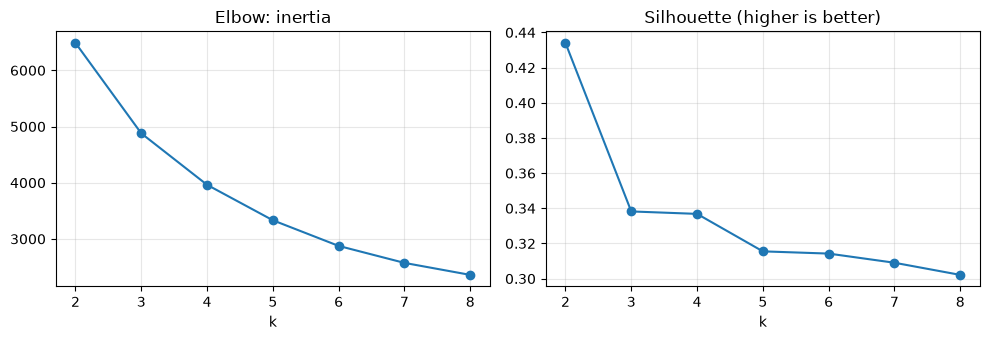

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
choice["inertia"].plot(ax=ax[0], marker="o", title="Elbow: inertia")
choice["silhouette"].plot(ax=ax[1], marker="o", title="Silhouette (higher is better)")
for a in ax: a.set_xlabel("k"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Choice: k = 4.** Silhouette is highest at k = 2, but two groups ("active" and "inactive") are too coarse to plan campaigns with. Between 3 and 8 the silhouette is nearly flat (0.34 at both 3 and 4, slowly falling after), and the elbow bends around 3–4. So the data does not strongly prefer any k above 2 (lesson 06.7 showed customers form a continuum). k = 4 gives segments marketing can act on differently, at no real cost in silhouette.

## Task 3 · Profile and name the segments

In [6]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(rfm_scaled)
rfm["cluster"] = km.labels_
profile = rfm.groupby("cluster").agg(customers=("recency", "size"), recency=("recency", "median"),
                                     frequency=("frequency", "median"), monetary=("monetary", "median"),
                                     revenue=("monetary", "sum"))
profile["revenue_share"] = profile["revenue"] / profile["revenue"].sum()
profile.round(2)

,customers,recency,frequency,monetary,revenue,revenue_share
cluster,,,,,,
0,699,8.0,10.0,3750.40,5727810.03,0.64
1,1635,173.0,1.0,296.64,562832.89,0.06
2,826,16.0,2.0,480.11,459107.32,0.05
3,1178,53.5,4.0,1351.82,2137476.65,0.24


In [7]:
# Name by rule, not by cluster number (cluster numbers can change between runs).
names = {}
names[profile["monetary"].idxmax()] = "Champions"
names[profile["recency"].idxmax()] = "Lapsed one-timers"
rest = profile.drop(index=list(names))
names[rest["recency"].idxmin()] = "Newcomers"
names[rest["recency"].idxmax()] = "Regulars, cooling"
rfm["segment"] = rfm["cluster"].map(names)
profile.index = profile.index.map(names)
profile.sort_values("monetary", ascending=False).round(2)

,customers,recency,frequency,monetary,revenue,revenue_share
cluster,,,,,,
Champions,699,8.0,10.0,3750.40,5727810.03,0.64
"Regulars, cooling",1178,53.5,4.0,1351.82,2137476.65,0.24
Newcomers,826,16.0,2.0,480.11,459107.32,0.05
Lapsed one-timers,1635,173.0,1.0,296.64,562832.89,0.06


- **Champions**: ordered within the last week or so, about 10 orders, median spend around £3,750. The smallest segment by count, but most of the revenue.
- **Regulars, cooling**: a few orders, last seen about two months ago, mid-level spend.
- **Newcomers**: ordered recently but only once or twice, low spend so far.
- **Lapsed one-timers**: one order, about six months ago, low spend. The biggest segment by count, but only 6% of revenue.

These are the same four personas as in lesson 06.3 (same data, same k, same seed): the segment sizes and revenue shares match that lesson. Lesson 06.3 shows *means* per segment; this table shows *medians*, which are less pulled by the few huge customers, so those columns differ.

## Task 4 · Draw the segments

PC1 weights (R, F, M): [-0.51  0.62  0.6 ]  variance ratio: [0.752 0.187]


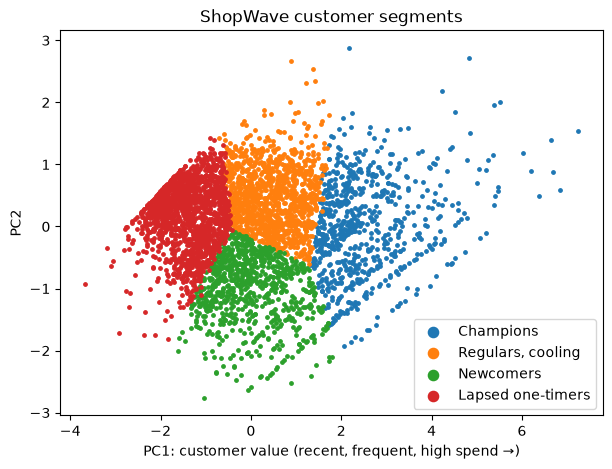

In [8]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit(rfm_scaled)
xy = pca.transform(rfm_scaled)
print("PC1 weights (R, F, M):", pca.components_[0].round(2), " variance ratio:", pca.explained_variance_ratio_.round(3))
plt.figure(figsize=(7, 5))
for name in ["Champions", "Regulars, cooling", "Newcomers", "Lapsed one-timers"]:
    m = (rfm["segment"] == name).values
    plt.scatter(xy[m, 0], xy[m, 1], s=6, label=name)
plt.xlabel("PC1: customer value (recent, frequent, high spend →)"); plt.ylabel("PC2")
plt.legend(markerscale=3); plt.title("ShopWave customer segments"); plt.show()

PC1 gives negative weight to recency and positive weight to frequency and spend: it is a **customer value** axis. Champions sit at the right, lapsed one-timers at the left, and the other two segments in between, separated mostly by PC2 (recent-but-small vs older-but-bigger).

## Task 5 · Flag odd invoices

In [9]:
# Lesson 06.8 showed that manual adjustments and postage dominate any anomaly list. Remove them first.
non_product = ["M", "POST", "DOT", "C2", "BANK CHARGES", "AMAZONFEE", "D", "CRUK", "PADS"]
removed = sales["StockCode"].isin(non_product)
print(f"removing {removed.sum():,} non-product lines ({removed.mean():.1%})")
sales = sales[~removed]

inv = sales.groupby("Invoice").agg(
    customer=("Customer ID", "first"), country=("Country", "first"),
    when=("InvoiceDate", "first"), amount=("Revenue", "sum"),
    items=("Quantity", "sum"), lines=("StockCode", "nunique"), max_price=("Price", "max"))
inv["hour"] = inv["when"].dt.hour
inv["avg_price"] = inv["amount"] / inv["items"]
print(f"{len(inv):,} invoices")

removing 1,543 non-product lines (0.4%)
18,402 invoices


In [10]:
from sklearn.ensemble import IsolationForest
features = ["amount", "items", "avg_price", "hour"]
X_inv = np.log1p(inv[features])
iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42).fit(X_inv)
inv["score"] = -iso.score_samples(X_inv)
inv["flag"] = iso.predict(X_inv) == -1
inv = inv.join(sales.groupby("Invoice")["Description"].first().rename("first_product"))
print(f"flagged {inv['flag'].sum()} of {len(inv):,} invoices")
inv.sort_values("score", ascending=False).head(10)[
    ["customer", "country", "amount", "items", "avg_price", "hour", "first_product", "score"]].round(2)

flagged 185 of 18,402 invoices


,customer,country,amount,items,avg_price,hour,first_product,score
Invoice,,,,,,,,
577130,15861,United Kingdom,165.00,1,165.00,19,RUSTIC SEVENTEEN DRAWER SIDEBOARD,0.75
536835,13145,United Kingdom,295.00,1,295.00,18,VINTAGE RED KITCHEN CABINET,0.74
545900,17817,United Kingdom,195.00,1,195.00,17,LOVE SEAT ANTIQUE WHITE METAL,0.73
556266,13900,United Kingdom,8.50,1,8.50,19,BLACK KITCHEN SCALES,0.72
556446,15098,United Kingdom,649.50,1,649.50,15,PICNIC BASKET WICKER 60 PIECES,0.72
556267,13694,United Kingdom,3027.31,9811,0.31,19,CLASSIC FRENCH STYLE BASKET NATURAL,0.72
561680,18268,United Kingdom,25.50,2,12.75,19,SET OF 16 VINTAGE ROSE CUTLERY,0.72
573161,17736,United Kingdom,39.95,1,39.95,9,SET/4 WHITE RETRO STORAGE CUBES,0.71
545902,15834,United Kingdom,250.00,2,125.00,17,VINTAGE RED KITCHEN CABINET,0.71


In [11]:
flagged = inv[inv["flag"]]
pd.DataFrame({"flagged median": flagged[features].median(), "all median": inv[features].median()}).round(2)

,flagged median,all median
amount,21.0,301.65
items,2.0,156.00
avg_price,8.5,1.87
hour,14.0,12.00


With adjustments and postage removed, the flags are genuine product orders with an unusual shape. The median flagged invoice is 2 items for £21 at £8.50 each; the median invoice overall is 156 items for £302 at £1.87 each. The top of the list is single furniture pieces (a sideboard, a kitchen cabinet, a chest of drawers), several placed in the evening. Typical ShopWave invoices are wholesale-like, so a retail-style order of one expensive item stands out. These are worth a quick look by the finance team, not proof of fraud.

## Task 6 · Connect flags to segments

In [12]:
inv["segment"] = inv["customer"].map(rfm["segment"])
compare = pd.DataFrame({
    "share of flagged invoices": inv.loc[inv["flag"], "segment"].value_counts(normalize=True),
    "share of all invoices": inv["segment"].value_counts(normalize=True)})
compare["over-representation"] = compare["share of flagged invoices"] / compare["share of all invoices"]
compare.round(3).sort_values("over-representation", ascending=False)

,share of flagged invoices,share of all invoices,over-representation
segment,,,
"Regulars, cooling",0.286,0.263,1.090
Lapsed one-timers,0.124,0.116,1.068
Champions,0.524,0.523,1.002
Newcomers,0.065,0.098,0.665


Read the last column: above 1 means the segment produces more than its share of odd invoices. Every ratio is close to 1 (between about 0.7 and 1.1): flagged invoices come from all segments roughly in proportion to how many invoices each segment places. Champions place about half of all invoices and about half of the flagged ones. Newcomers are, if anything, slightly *under*-represented.

That is a useful negative result. Before looking, it is tempting to assume odd orders come from new or one-off customers. The data says no: an unusual invoice tells you about the **order**, not about the kind of customer. Reviewers should judge each flagged invoice on its own, rather than treating some segments as suspicious.

## Task 7 · Marketing summary

In [13]:
summary = profile.loc[["Champions", "Regulars, cooling", "Newcomers", "Lapsed one-timers"]]
for name, row in summary.iterrows():
    print(f"{name:<18} {row['customers']:>5.0f} customers ({row['customers'] / summary['customers'].sum():.0%}), "
          f"{row['revenue_share']:.0%} of revenue, median {row['frequency']:.0f} orders, "
          f"£{row['monetary']:,.0f} spent, last order {row['recency']:.0f} days ago")
print(f"\nAnomaly review list: {inv['flag'].sum()} invoices in 12 months, about {inv['flag'].sum() / 12:.0f} per month")

Champions            699 customers (16%), 64% of revenue, median 10 orders, £3,750 spent, last order 8 days ago
Regulars, cooling   1178 customers (27%), 24% of revenue, median 4 orders, £1,352 spent, last order 54 days ago
Newcomers            826 customers (19%), 5% of revenue, median 2 orders, £480 spent, last order 16 days ago
Lapsed one-timers   1635 customers (38%), 6% of revenue, median 1 orders, £297 spent, last order 173 days ago

Anomaly review list: 185 invoices in 12 months, about 15 per month


### ShopWave customer segments: summary for marketing

*(Figures from the cell above.)*

**Champions.** 699 customers (16%) who ordered in the last week or so, about 10 times, and bring in **64% of revenue**. **Action:** protect them. Early access to new ranges, a named account contact for the biggest, and no generic discount emails (they buy anyway).

**Regulars, cooling.** Several orders, last seen about two months ago, mid-level spend. **Action:** nudge them towards Champion behaviour: "complete the set" recommendations (lessons 06.9–06.10) and a reminder when their usual reorder time passes.

**Newcomers.** Ordered recently but only once or twice. **Action:** the second order is the hardest. A welcome series with recommendations based on their first basket, and a small incentive on order two.

**Lapsed one-timers.** The largest group: 1,635 customers (38%) with one order about six months ago, bringing in only 6% of revenue. **Action:** one low-cost win-back email; do not spend heavily here. The churn model from Module 05 can pick out the few worth more effort.

**Anomaly review list.** About 15 invoices a month are flagged as unusual after removing manual adjustments and postage. They are mostly orders of just one or two items at a high price each, and they come from all segments in proportion to their order volume, not mainly from new customers. **Action:** the finance team reviews them weekly (a few minutes each). After two months, record which were genuine problems, and use those labels to tune the contamination level or train a supervised model.

**Caveat.** Segments are a convenient cut of a continuum (lesson 06.7), not natural types. Re-run monthly and watch customers move between segments; that movement is often more useful than the segments themselves.